# TP — Classification d’images par réseaux de neurones convolutifs (CNN)
## Dataset : Natural Images (8 classes)

**Objectif :** explorer les images, préparer les données, construire un CNN initial, l’évaluer, l’améliorer, comparer les modèles et tester une image externe.

> **Avant de commencer :** adaptez `DATASET_DIR` à l’emplacement du dossier `natural_images` sur votre ordinateur. Le dossier doit contenir un sous-dossier par classe (`airplane`, `car`, `cat`, `dog`, `flower`, `fruit`, `motorbike`, `person`).
>
> Le notebook crée les partitions train/validation/test à partir des images disponibles. Il conserve les mêmes partitions pour les deux modèles afin que la comparaison soit équitable.

## 0. Imports et configuration

In [2]:
# Si nécessaire, exécutez dans une cellule séparée :
# %pip install tensorflow scikit-learn matplotlib seaborn pandas pillow

import os
import time
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, UnidentifiedImageError

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, precision_recall_fscore_support
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

IMG_SIZE = (150, 150)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# MODIFIEZ ce chemin selon votre ordinateur.
DATASET_DIR = Path(r"C:\Users\hp\Desktop\sdia\S3\Framewok DL\archive\natural_images")

print("TensorFlow :", tf.__version__)
print("Dataset :", DATASET_DIR)
print("Dossier trouvé :", DATASET_DIR.exists())

TensorFlow : 2.21.0
Dataset : C:\Users\hp\Desktop\sdia\S3\Framewok DL\archive\natural_images
Dossier trouvé : True


## Partie 1 — Exploration du dataset

### 1.1 Repérer les classes et compter les images

Nombre total d'images trouvées : 6899
Nombre de classes : 8
Classes : ['airplane', 'car', 'cat', 'dog', 'flower', 'fruit', 'motorbike', 'person']


,filepath,class_name
0,C:\Users\hp\Desktop\sdia\S3\Framewok DL\archiv...,airplane
1,C:\Users\hp\Desktop\sdia\S3\Framewok DL\archiv...,airplane
2,C:\Users\hp\Desktop\sdia\S3\Framewok DL\archiv...,airplane
3,C:\Users\hp\Desktop\sdia\S3\Framewok DL\archiv...,airplane
4,C:\Users\hp\Desktop\sdia\S3\Framewok DL\archiv...,airplane


,nombre_images
class_name,
airplane,727
car,968
cat,885
dog,702
flower,843
fruit,1000
motorbike,788
person,986


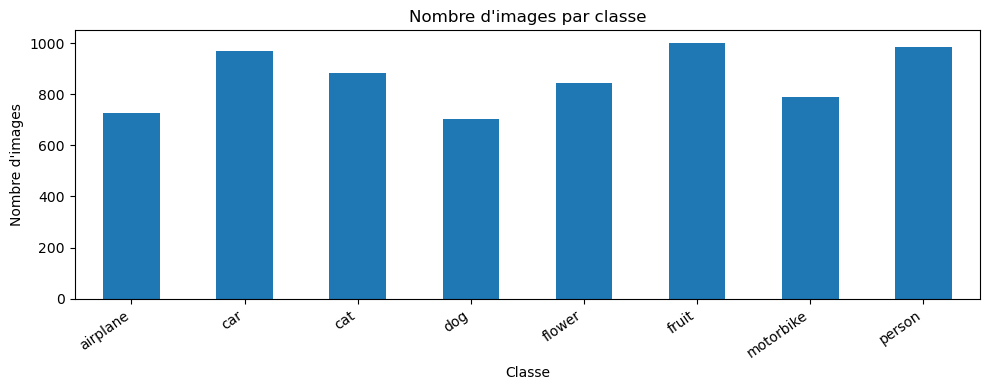

In [3]:
if not DATASET_DIR.exists():
    raise FileNotFoundError(
        f"Dossier introuvable : {DATASET_DIR}\n"
        "Modifiez DATASET_DIR dans la cellule de configuration."
    )

SUPPORTED_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".gif"}

# Chaque sous-dossier direct représente une classe.
class_dirs = sorted([p for p in DATASET_DIR.iterdir() if p.is_dir()])
if not class_dirs:
    raise ValueError("Aucun sous-dossier de classe trouvé dans DATASET_DIR.")

class_names = [p.name for p in class_dirs]
image_paths, image_labels = [], []

for class_name in class_names:
    for p in sorted((DATASET_DIR / class_name).rglob("*")):
        if p.is_file() and p.suffix.lower() in SUPPORTED_EXTENSIONS:
            image_paths.append(str(p))
            image_labels.append(class_name)

df = pd.DataFrame({"filepath": image_paths, "class_name": image_labels})
print(f"Nombre total d'images trouvées : {len(df)}")
print(f"Nombre de classes : {len(class_names)}")
print("Classes :", class_names)
display(df.head())

counts = df["class_name"].value_counts().reindex(class_names, fill_value=0)
display(counts.rename("nombre_images").to_frame())

plt.figure(figsize=(10, 4))
counts.plot(kind="bar")
plt.title("Nombre d'images par classe")
plt.xlabel("Classe")
plt.ylabel("Nombre d'images")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

### 1.2 Visualiser au moins 9 images avec leurs étiquettes

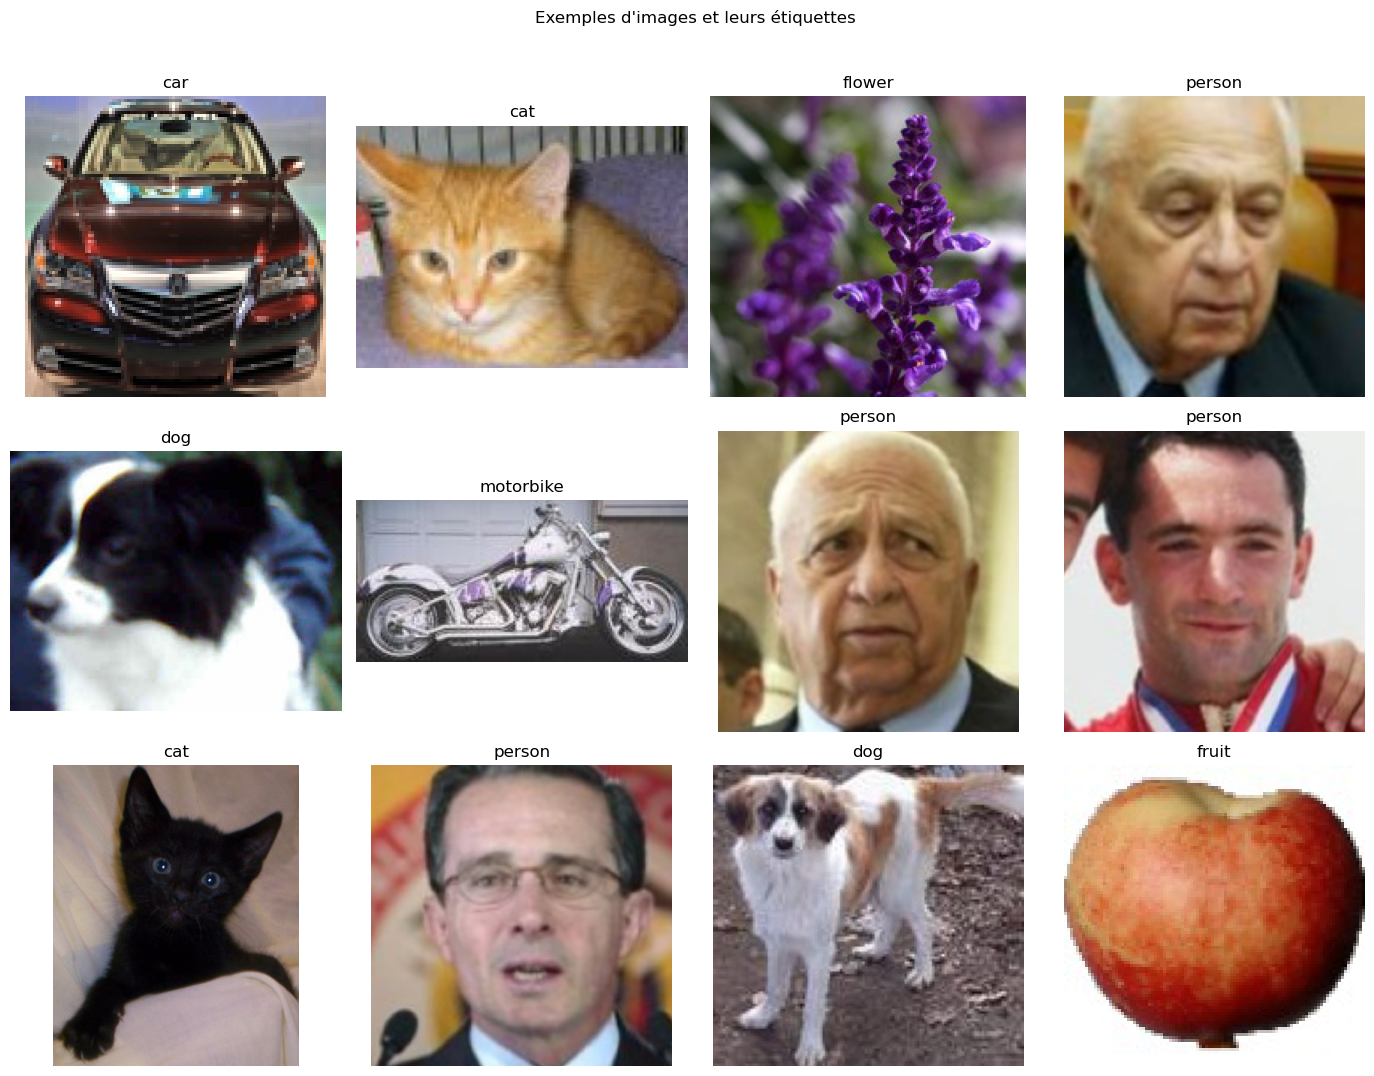

In [4]:
n = min(12, len(df))
sample_df = df.sample(n=n, random_state=SEED)
cols = 4
rows = int(np.ceil(n / cols))
plt.figure(figsize=(14, 3.5 * rows))

for i, (_, row) in enumerate(sample_df.iterrows(), start=1):
    try:
        img = Image.open(row["filepath"]).convert("RGB")
        plt.subplot(rows, cols, i)
        plt.imshow(img)
        plt.title(row["class_name"])
        plt.axis("off")
    except Exception as e:
        print("Image illisible :", row["filepath"], e)

plt.suptitle("Exemples d'images et leurs étiquettes", y=1.02)
plt.tight_layout()
plt.show()

### 1.3 Dimensions, modes et formats des images

In [5]:
dimensions, modes, formats = [], [], []
bad_images = []

for path in df["filepath"]:
    try:
        with Image.open(path) as im:
            dimensions.append(im.size)       # (largeur, hauteur)
            modes.append(im.mode)             # RGB, RGBA, L, etc.
            formats.append(im.format)
    except (UnidentifiedImageError, OSError) as e:
        bad_images.append((path, str(e)))

dim_counts = Counter(dimensions)
mode_counts = Counter(modes)
format_counts = Counter(formats)

print("Dimensions les plus fréquentes (largeur, hauteur) :")
display(pd.DataFrame(dim_counts.most_common(10), columns=["dimensions", "nombre"]))
print("Modes colorimétriques :", mode_counts)
print("Formats :", format_counts)
print("Images illisibles :", len(bad_images))

if bad_images:
    display(pd.DataFrame(bad_images, columns=["fichier", "erreur"]).head(10))

Dimensions les plus fréquentes (largeur, hauteur) :


,dimensions,nombre
0,"(100, 100)",1968
1,"(256, 256)",983
2,"(197, 108)",6
3,"(294, 89)",5
4,"(291, 89)",4
5,"(299, 96)",4
6,"(500, 375)",4
7,"(191, 121)",4
8,"(194, 109)",4
9,"(193, 109)",4


Modes colorimétriques : Counter({'RGB': 6899})
Formats : Counter({'JPEG': 6898, 'PNG': 1})
Images illisibles : 0


### 1.4 Difficultés potentielles du dataset

À commenter après observation des résultats :

- **Déséquilibre des classes :** certaines classes peuvent contenir plus d'images que d'autres.
- **Variabilité visuelle :** taille, cadrage, arrière-plan, luminosité, orientation et distance du sujet.
- **Similarité entre classes :** des objets peuvent partager des formes ou couleurs.
- **Qualité des données :** images corrompues, fichiers au mauvais format ou étiquettes incorrectes.
- **Généralisation :** le modèle peut apprendre des détails de l'arrière-plan au lieu de l'objet.
- **Taille du dataset :** 6 899 images au total est une quantité modérée pour un CNN entraîné depuis zéro.

## Partie 2 — Prétraitement et séparation des données

Nous utilisons une séparation stratifiée **70 % entraînement, 15 % validation, 15 % test**. La stratification conserve autant que possible la proportion de chaque classe dans chaque partition. Les images sont redimensionnées à 150 × 150. La normalisation `Rescaling(1./255)` sera intégrée aux modèles : les pixels passent de l'intervalle [0, 255] à [0, 1].

In [6]:
# Écarter les images illisibles détectées pendant l'inspection.
if bad_images:
    bad_paths = {item[0] for item in bad_images}
    df = df[~df["filepath"].isin(bad_paths)].reset_index(drop=True)

# Encoder les classes sous forme d'entiers : 0, 1, ..., nombre_classes - 1.
class_names = sorted(df["class_name"].unique())
class_to_index = {name: idx for idx, name in enumerate(class_names)}
df["label"] = df["class_name"].map(class_to_index).astype(int)
NUM_CLASSES = len(class_names)

train_df, temp_df = train_test_split(
    df, test_size=0.30, random_state=SEED, stratify=df["label"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=SEED, stratify=temp_df["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f"Train : {len(train_df)} images ({len(train_df)/len(df):.1%})")
print(f"Validation : {len(val_df)} images ({len(val_df)/len(df):.1%})")
print(f"Test : {len(test_df)} images ({len(test_df)/len(df):.1%})")
print("Classes dans l'ordre utilisé :", class_names)

for split_name, split_df in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    print(f"\n{split_name} — nombre par classe")
    display(split_df["class_name"].value_counts().reindex(class_names, fill_value=0).to_frame("nombre"))

Train : 4829 images (70.0%)
Validation : 1035 images (15.0%)
Test : 1035 images (15.0%)
Classes dans l'ordre utilisé : ['airplane', 'car', 'cat', 'dog', 'flower', 'fruit', 'motorbike', 'person']

Train — nombre par classe


,nombre
class_name,
airplane,509
car,678
cat,619
dog,491
flower,590
fruit,700
motorbike,552
person,690



Validation — nombre par classe


,nombre
class_name,
airplane,109
car,145
cat,133
dog,105
flower,127
fruit,150
motorbike,118
person,148



Test — nombre par classe


,nombre
class_name,
airplane,109
car,145
cat,133
dog,106
flower,126
fruit,150
motorbike,118
person,148


### 2.1 Construire les pipelines TensorFlow

In [7]:
def load_image(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    # Rescaling est appliqué dans le modèle, pas ici.
    image = tf.cast(image, tf.float32)
    return image, tf.cast(label, tf.int32)

def make_dataset(frame, training=False):
    paths = frame["filepath"].to_numpy()
    labels = frame["label"].to_numpy(dtype=np.int32)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

# Vérification image-étiquette sur un batch.
images_batch, labels_batch = next(iter(train_ds))
print("Forme d'un batch d'images :", images_batch.shape)
print("Forme du batch d'étiquettes :", labels_batch.shape)
print("Min/max pixels avant Rescaling :", float(tf.reduce_min(images_batch)), float(tf.reduce_max(images_batch)))
print("Étiquettes présentes dans le batch :", np.unique(labels_batch.numpy()))

Forme d'un batch d'images : (32, 150, 150, 3)
Forme du batch d'étiquettes : (32,)
Min/max pixels avant Rescaling : 0.0 255.0
Étiquettes présentes dans le batch : [0 1 2 3 4 5 6 7]


### 2.2 Pourquoi normaliser ?

Une image RGB possède généralement des valeurs de pixels comprises entre 0 et 255. `Rescaling(1./255)` divise chaque valeur par 255 pour obtenir [0, 1]. Cela met les entrées sur une échelle plus adaptée à l'optimisation, peut stabiliser et accélérer l'apprentissage, et évite de fournir au réseau des valeurs inutilement grandes. La normalisation ne change pas l'étiquette de l'image.

## Partie 3 — Construction du CNN initial

Le modèle initial respecte l'architecture demandée : trois convolutions de 32, 64 et 128 filtres, chacune suivie de MaxPooling2D, puis GlobalAveragePooling2D, Dense(64, ReLU) et une sortie Softmax. `Rescaling` est placé au début du modèle.

In [8]:
def build_initial_cnn():
    inputs = keras.Input(shape=(150, 150, 3), name="image")
    x = layers.Rescaling(1./255, name="normalisation")(inputs)

    x = layers.Conv2D(32, kernel_size=3, padding="same", activation="relu", name="conv_32")(x)
    x = layers.MaxPooling2D(name="pool_1")(x)

    x = layers.Conv2D(64, kernel_size=3, padding="same", activation="relu", name="conv_64")(x)
    x = layers.MaxPooling2D(name="pool_2")(x)

    x = layers.Conv2D(128, kernel_size=3, padding="same", activation="relu", name="conv_128")(x)
    x = layers.MaxPooling2D(name="pool_3")(x)

    x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
    x = layers.Dense(64, activation="relu", name="dense_64")(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="classification")(x)

    return keras.Model(inputs, outputs, name="CNN_initial")

initial_model = build_initial_cnn()
initial_model.compile(
    optimizer=keras.optimizers.Adam(),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
initial_model.summary()

Model: "CNN_initial"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalisation (Rescaling)       │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_32 (Conv2D)                │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_64 (Conv2D)                │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_128 (Conv2D)               │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_3 (MaxPooling2D)           │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification (Dense)          │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102,024 (398.53 KB)

 Trainable params: 102,024 (398.53 KB)

 Non-trainable params: 0 (0.00 B)

## Partie 4 — Entraînement et évaluation du CNN initial

In [ ]:
EPOCHS_INITIAL = 20

callbacks_initial = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1
    )
]

start = time.perf_counter()
history_initial = initial_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_INITIAL,
    callbacks=callbacks_initial,
    verbose=1
)
time_initial = time.perf_counter() - start
print(f"Temps d'entraînement du CNN initial : {time_initial:.1f} secondes")

Epoch 1/20


c:\Users\hp\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


151/151 ━━━━━━━━━━━━━━━━━━━━ 54s 343ms/step - accuracy: 0.3821 - loss: 1.6300 - val_accuracy: 0.5498 - val_loss: 1.2482 - learning_rate: 0.0010
Epoch 2/20
151/151 ━━━━━━━━━━━━━━━━━━━━ 54s 360ms/step - accuracy: 0.5865 - loss: 1.1457 - val_accuracy: 0.6193 - val_loss: 1.1357 - learning_rate: 0.0010
Epoch 3/20
151/151 ━━━━━━━━━━━━━━━━━━━━ 62s 408ms/step - accuracy: 0.6747 - loss: 0.9224 - val_accuracy: 0.6947 - val_loss: 0.8524 - learning_rate: 0.0010
Epoch 4/20
151/151 ━━━━━━━━━━━━━━━━━━━━ 69s 460ms/step - accuracy: 0.7117 - loss: 0.7887 - val_accuracy: 0.7353 - val_loss: 0.7513 - learning_rate: 0.0010
Epoch 5/20
151/151 ━━━━━━━━━━━━━━━━━━━━ 57s 377ms/step - accuracy: 0.7625 - loss: 0.6563 - val_accuracy: 0.7768 - val_loss: 0.6245 - learning_rate: 0.0010
Epoch 6/20
151/151 ━━━━━━━━━━━━━━━━━━━━ 51s 340ms/step - accuracy: 0.7832 - loss: 0.5953 - val_accuracy: 0.7478 - val_loss: 0.6392 - learning_rate: 0.0010
Epoch 7/20
151/151 ━━━━━━━━━━━━━━━━━━━━ 50s 334ms/step - accuracy: 0.8039 - loss:

### 4.1 Courbes d'accuracy et de loss

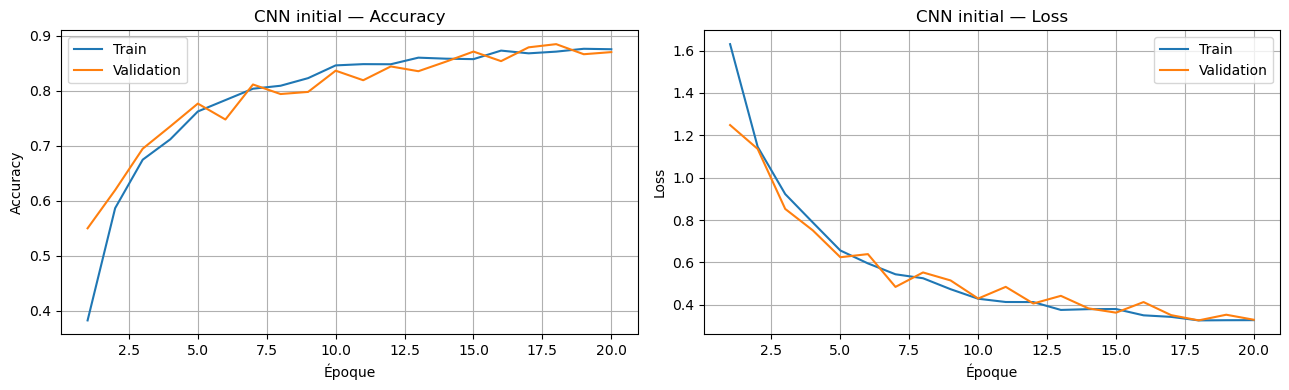

In [10]:
def plot_history(history, title):
    hist = pd.DataFrame(history.history)
    epochs = np.arange(1, len(hist) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(epochs, hist["accuracy"], label="Train")
    axes[0].plot(epochs, hist["val_accuracy"], label="Validation")
    axes[0].set_title(f"{title} — Accuracy")
    axes[0].set_xlabel("Époque")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(epochs, hist["loss"], label="Train")
    axes[1].plot(epochs, hist["val_loss"], label="Validation")
    axes[1].set_title(f"{title} — Loss")
    axes[1].set_xlabel("Époque")
    axes[1].set_ylabel("Loss")
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()

plot_history(history_initial, "CNN initial")

### 4.2 Repérer l'overfitting

Un signe fréquent d'overfitting est une accuracy d'entraînement qui continue à augmenter tandis que l'accuracy de validation stagne ou diminue. De même, la loss d'entraînement diminue alors que la loss de validation remonte. Un écart important et persistant entre les courbes indique que le modèle apprend mieux les images vues que les images non vues. L'`EarlyStopping` limite ce risque en restaurant les poids de la meilleure époque de validation.

### 4.3 Évaluation finale sur le jeu de test

In [11]:
def collect_predictions(model, dataset):
    y_true, y_prob = [], []
    for images, labels in dataset:
        probs = model.predict(images, verbose=0)
        y_true.extend(labels.numpy().tolist())
        y_prob.extend(probs.tolist())
    return np.array(y_true), np.array(y_prob)

y_test, prob_initial = collect_predictions(initial_model, test_ds)
pred_initial = prob_initial.argmax(axis=1)

test_loss_initial, test_acc_initial = initial_model.evaluate(test_ds, verbose=0)
print(f"Test loss du CNN initial : {test_loss_initial:.4f}")
print(f"Test accuracy du CNN initial : {test_acc_initial:.4f}")
print("\nRapport de classification :")
print(classification_report(
    y_test, pred_initial, labels=list(range(NUM_CLASSES)),
    target_names=class_names, zero_division=0
))

Test loss du CNN initial : 0.3413
Test accuracy du CNN initial : 0.8763

Rapport de classification :
              precision    recall  f1-score   support

    airplane       0.82      0.94      0.88       109
         car       0.93      0.98      0.95       145
         cat       0.74      0.54      0.63       133
         dog       0.63      0.63      0.63       106
      flower       0.91      0.93      0.92       126
       fruit       0.99      1.00      0.99       150
   motorbike       0.93      0.94      0.93       118
      person       0.95      0.99      0.97       148

    accuracy                           0.88      1035
   macro avg       0.86      0.87      0.86      1035
weighted avg       0.87      0.88      0.87      1035



### 4.4 Matrice de confusion

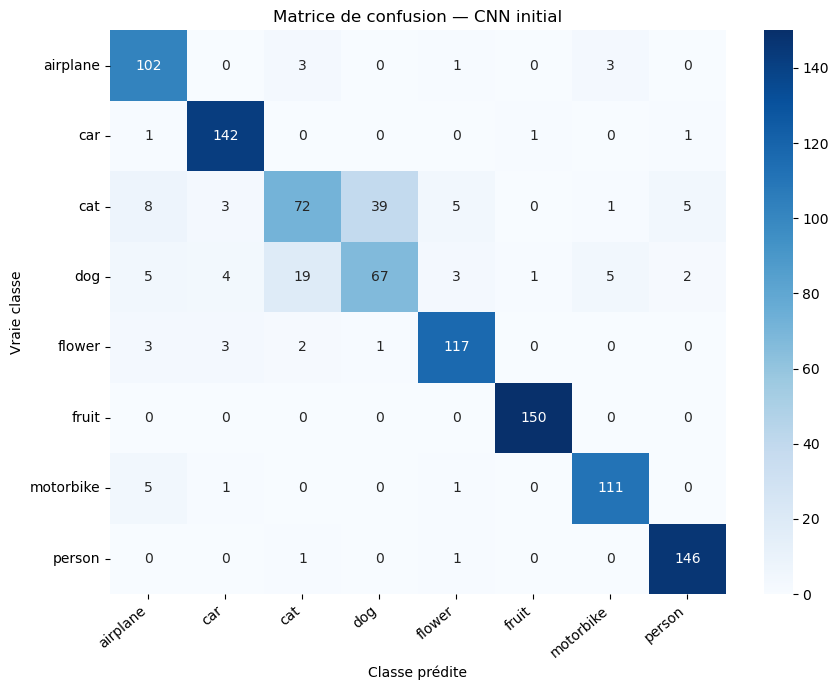

In [12]:
def show_confusion_matrix(y_true, y_pred, class_names, title):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(class_names))))
    plt.figure(figsize=(9, 7))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=class_names, yticklabels=class_names
    )
    plt.title(title)
    plt.xlabel("Classe prédite")
    plt.ylabel("Vraie classe")
    plt.xticks(rotation=40, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()
    return cm

cm_initial = show_confusion_matrix(y_test, pred_initial, class_names, "Matrice de confusion — CNN initial")

**Interprétation :** la diagonale contient les prédictions correctes. Les valeurs hors diagonale représentent les erreurs. Repérez les paires de classes souvent confondues et reliez-les, si possible, à leurs ressemblances visuelles. Le rapport de classification fournit précision, rappel et F1-score par classe.

## Partie 5 — Amélioration du CNN

Nous ajoutons une **augmentation de données** (retournement horizontal, petite rotation et zoom) uniquement pendant l'entraînement, ainsi que `BatchNormalization` et `Dropout` pour aider à limiter l'overfitting. Le test et la validation ne sont pas augmentés. Le découpage des données reste exactement le même.

In [13]:
def build_improved_cnn():
    inputs = keras.Input(shape=(150, 150, 3), name="image")

    # L'augmentation est active pendant l'entraînement uniquement.
    x = layers.RandomFlip("horizontal", seed=SEED, name="augmentation_flip")(inputs)
    x = layers.RandomRotation(0.08, seed=SEED, name="augmentation_rotation")(x)
    x = layers.RandomZoom(0.10, seed=SEED, name="augmentation_zoom")(x)

    x = layers.Rescaling(1./255, name="normalisation")(x)

    for filters, block in [(32, 1), (64, 2), (128, 3)]:
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False, name=f"conv_{filters}")(x)
        x = layers.BatchNormalization(name=f"batch_norm_{block}")(x)
        x = layers.Activation("relu", name=f"relu_{block}")(x)
        x = layers.MaxPooling2D(name=f"pool_{block}")(x)

    x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
    x = layers.Dense(128, activation="relu", name="dense_128")(x)
    x = layers.Dropout(0.40, name="dropout")(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="classification")(x)

    return keras.Model(inputs, outputs, name="CNN_ameliore")

improved_model = build_improved_cnn()
improved_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=5e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
improved_model.summary()

Model: "CNN_ameliore"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation_flip (RandomFlip)  │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation_rotation           │ (None, 150, 150, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation_zoom (RandomZoom)  │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalisation (Rescaling)       │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_32 (Conv2D)                │ (None, 150, 150, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_1                    │ (None, 150, 150, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_1 (Activation)             │ (None, 150, 150, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_1 (MaxPooling2D)           │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_64 (Conv2D)                │ (None, 75, 75, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_2                    │ (None, 75, 75, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_2 (Activation)             │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_2 (MaxPooling2D)           │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_128 (Conv2D)               │ (None, 37, 37, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_3                    │ (None, 37, 37, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu_3 (Activation)             │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_3 (MaxPooling2D)           │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_128 (Dense)               │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification (Dense)          │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,464 (435.41 KB)

 Trainable params: 111,016 (433.66 KB)

 Non-trainable params: 448 (1.75 KB)

### Entraîner le modèle amélioré

Epoch 1/25


c:\Users\hp\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


151/151 ━━━━━━━━━━━━━━━━━━━━ 135s 857ms/step - accuracy: 0.5676 - loss: 1.2421 - val_accuracy: 0.1449 - val_loss: 2.7976 - learning_rate: 5.0000e-04
Epoch 2/25
151/151 ━━━━━━━━━━━━━━━━━━━━ 144s 953ms/step - accuracy: 0.7171 - loss: 0.8224 - val_accuracy: 0.3208 - val_loss: 2.5226 - learning_rate: 5.0000e-04
Epoch 3/25
151/151 ━━━━━━━━━━━━━━━━━━━━ 117s 777ms/step - accuracy: 0.7685 - loss: 0.6762 - val_accuracy: 0.5710 - val_loss: 1.2532 - learning_rate: 5.0000e-04
Epoch 4/25
151/151 ━━━━━━━━━━━━━━━━━━━━ 137s 743ms/step - accuracy: 0.7836 - loss: 0.6099 - val_accuracy: 0.7633 - val_loss: 0.6114 - learning_rate: 5.0000e-04
Epoch 5/25
151/151 ━━━━━━━━━━━━━━━━━━━━ 108s 718ms/step - accuracy: 0.8074 - loss: 0.5359 - val_accuracy: 0.7575 - val_loss: 0.7364 - learning_rate: 5.0000e-04
Epoch 6/25
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 686ms/step - accuracy: 0.8269 - loss: 0.4816
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
151/151 ━━━━━━━━━━━━━━━━━━━━ 143s 722ms/step - 

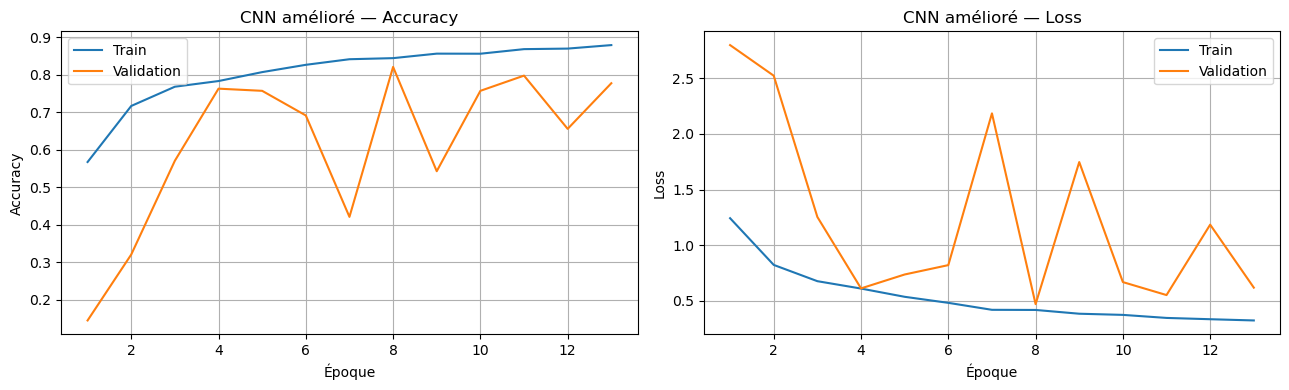

In [14]:
EPOCHS_IMPROVED = 25

callbacks_improved = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1
    )
]

start = time.perf_counter()
history_improved = improved_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_IMPROVED,
    callbacks=callbacks_improved,
    verbose=1
)
time_improved = time.perf_counter() - start
print(f"Temps d'entraînement du CNN amélioré : {time_improved:.1f} secondes")

plot_history(history_improved, "CNN amélioré")

## Partie 5 bis — Transfer Learning avec MobileNetV2

Le **Transfer Learning** utilise un réseau pré-entraîné sur ImageNet comme extracteur de caractéristiques. On garde d'abord sa base convolutive gelée et on entraîne une nouvelle tête de classification adaptée aux 8 classes de Natural Images. Ensuite, on dégèle seulement une petite partie finale de la base et on affine le modèle avec un taux d'apprentissage très faible.

**Important :** MobileNetV2 attend des pixels prétraités dans l'intervalle [-1, 1]. La fonction `preprocess_input` est donc utilisée dans ce modèle ; il ne faut pas ajouter `Rescaling(1./255)` à sa place. Les mêmes partitions train/validation/test sont conservées pour une comparaison équitable.


In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

def load_image_transfer(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    return image, tf.cast(label, tf.int32)

def make_transfer_dataset(frame, training=False):
    paths = frame["filepath"].to_numpy()
    labels = frame["label"].to_numpy(dtype=np.int32)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image_transfer, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds_transfer = make_transfer_dataset(train_df, training=True)
val_ds_transfer = make_transfer_dataset(val_df)
test_ds_transfer = make_transfer_dataset(test_df)

def build_transfer_model():
    inputs = keras.Input(shape=(150, 150, 3), name="image")
    x = layers.RandomFlip("horizontal", seed=SEED)(inputs)
    x = layers.RandomRotation(0.05, seed=SEED)(x)
    x = layers.Rescaling(1./127.5, offset=-1, name="mobilenet_preprocessing")(x)

    base_model = MobileNetV2(
        input_shape=(150, 150, 3),
        include_top=False,
        weights="imagenet"
    )
    base_model.trainable = False
    # training=False maintient les statistiques BatchNormalization pré-entraînées.
    features = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(features)
    x = layers.Dropout(0.30)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="classification")(x)
    model = keras.Model(inputs, outputs, name="MobileNetV2_transfer")
    return model, base_model

transfer_model, transfer_base = build_transfer_model()
transfer_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
transfer_model.summary()


In [ ]:
EPOCHS_TRANSFER = 12
callbacks_transfer = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1
    )
]

start = time.perf_counter()
history_transfer = transfer_model.fit(
    train_ds_transfer,
    validation_data=val_ds_transfer,
    epochs=EPOCHS_TRANSFER,
    callbacks=callbacks_transfer,
    verbose=1
)

# Fine-tuning : dégeler uniquement les dernières couches de MobileNetV2.
transfer_base.trainable = True
for layer in transfer_base.layers[:-30]:
    layer.trainable = False
# Ne pas mettre à jour les statistiques BatchNormalization du modèle pré-entraîné.
for layer in transfer_base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

transfer_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

EPOCHS_FINE_TUNE = 8
start_finetune = time.perf_counter()
history_finetune = transfer_model.fit(
    train_ds_transfer,
    validation_data=val_ds_transfer,
    epochs=EPOCHS_FINE_TUNE,
    callbacks=callbacks_transfer,
    verbose=1
)
time_transfer = (time.perf_counter() - start) 
print(f"Temps total Transfer Learning + fine-tuning : {time_transfer:.1f} secondes")

# Combiner les historiques pour les graphiques et la comparaison.
history_transfer.history = {
    key: history_transfer.history.get(key, []) + history_finetune.history.get(key, [])
    for key in set(history_transfer.history) | set(history_finetune.history)
}
plot_history(history_transfer, "Transfer Learning — MobileNetV2")


## Partie 6 — Comparaison expérimentale

Pour sélectionner le modèle, on compare d'abord les performances de **validation**. Le jeu de test est réservé à l'évaluation finale et ne sert pas à choisir les hyperparamètres. Pour une comparaison parfaitement contrôlée, les deux modèles utilisent les mêmes fichiers train, validation et test.

In [15]:
summary_initial = best_validation_metrics(history_initial)
summary_improved = best_validation_metrics(history_improved)
summary_transfer = best_validation_metrics(history_transfer)

comparison = pd.DataFrame([
    {
        "Modèle": "CNN initial",
        "Paramètres": initial_model.count_params(),
        **summary_initial,
        "Temps entraînement (s)": time_initial
    },
    {
        "Modèle": "CNN amélioré",
        "Paramètres": improved_model.count_params(),
        **summary_improved,
        "Temps entraînement (s)": time_improved
    },
    {
        "Modèle": "Transfer Learning MobileNetV2",
        "Paramètres": transfer_model.count_params(),
        **summary_transfer,
        "Temps entraînement (s)": time_transfer
    }
])
display(comparison.round(4))


,Modèle,Paramètres,meilleure époque (val_loss),accuracy validation à cette époque,loss validation minimale,accuracy train à cette époque,loss train à cette époque,Temps entraînement (s)
0,CNN initial,102024,18,0.8850,0.3265,0.8714,0.3263,1253.0381
1,CNN amélioré,111464,8,0.8213,0.4699,0.8447,0.4177,1599.1082


### Comparer les courbes de validation

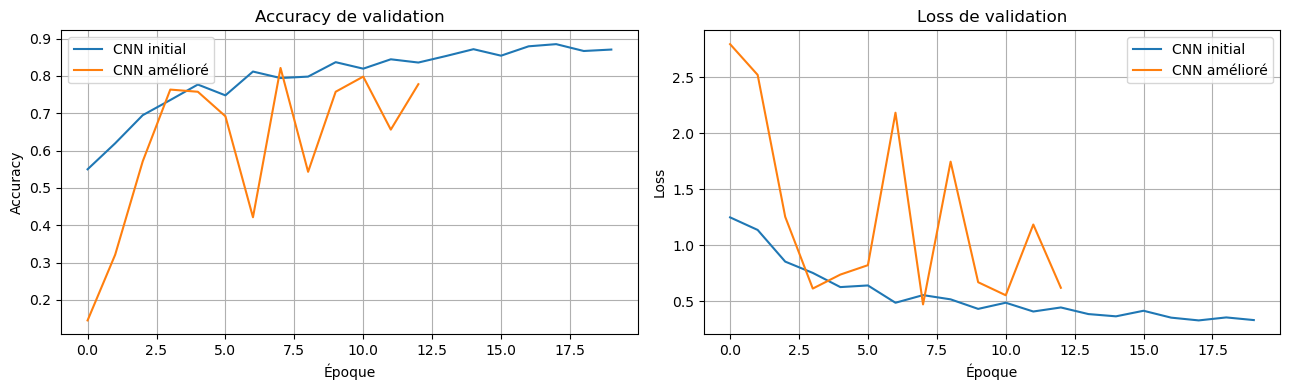

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for history, label in [
    (history_initial, "CNN initial"),
    (history_improved, "CNN amélioré"),
    (history_transfer, "Transfer Learning MobileNetV2")
]:
    axes[0].plot(history.history["val_accuracy"], label=label)
    axes[1].plot(history.history["val_loss"], label=label)

axes[0].set_title("Accuracy de validation")
axes[0].set_xlabel("Époque")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

axes[1].set_title("Loss de validation")
axes[1].set_xlabel("Époque")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


### 6.1 Choisir le modèle avec la validation, puis mesurer le test

Modèle sélectionné sur la validation : CNN initial
Résultat final sur test — CNN initial
Test loss : 0.3413
Test accuracy : 0.8763
              precision    recall  f1-score   support

    airplane       0.82      0.94      0.88       109
         car       0.93      0.98      0.95       145
         cat       0.74      0.54      0.63       133
         dog       0.63      0.63      0.63       106
      flower       0.91      0.93      0.92       126
       fruit       0.99      1.00      0.99       150
   motorbike       0.93      0.94      0.93       118
      person       0.95      0.99      0.97       148

    accuracy                           0.88      1035
   macro avg       0.86      0.87      0.86      1035
weighted avg       0.87      0.88      0.87      1035



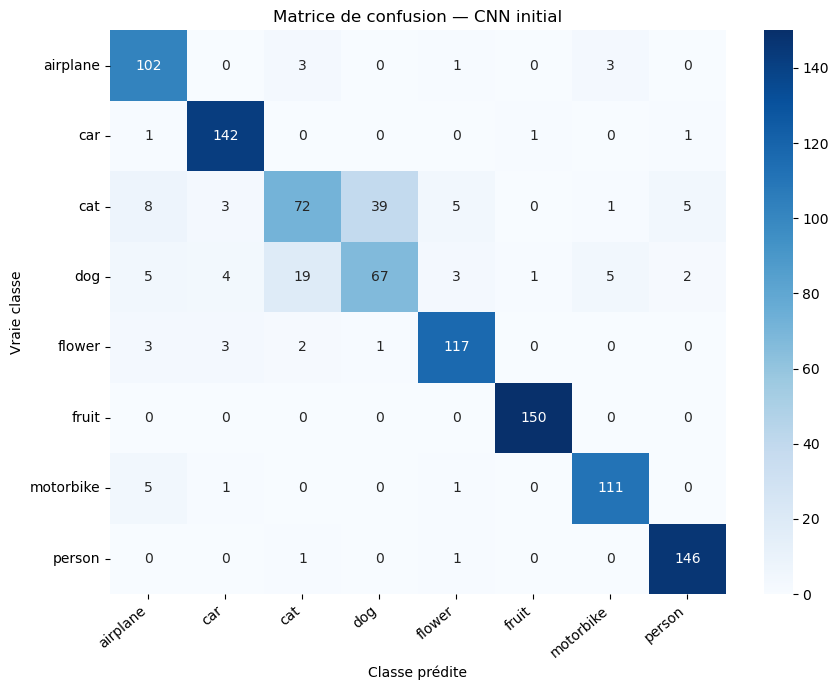

In [17]:
# Choisir le modèle avec la plus faible loss de validation.
validation_losses = {
    "CNN initial": summary_initial["loss validation minimale"],
    "CNN amélioré": summary_improved["loss validation minimale"],
    "Transfer Learning MobileNetV2": summary_transfer["loss validation minimale"]
}
selected_name = min(validation_losses, key=validation_losses.get)
model_by_name = {
    "CNN initial": initial_model,
    "CNN amélioré": improved_model,
    "Transfer Learning MobileNetV2": transfer_model
}
selected_model = model_by_name[selected_name]

print("Loss de validation par modèle :", validation_losses)
print("Modèle sélectionné sur la validation :", selected_name)

selected_test_loss, selected_test_acc = selected_model.evaluate(test_ds, verbose=0)
print(f"Résultat final sur test — {selected_name}")
print(f"Test loss : {selected_test_loss:.4f}")
print(f"Test accuracy : {selected_test_acc:.4f}")

y_test, prob_selected = collect_predictions(selected_model, test_ds)
pred_selected = prob_selected.argmax(axis=1)

print(classification_report(
    y_test, pred_selected, labels=list(range(NUM_CLASSES)),
    target_names=class_names, zero_division=0
))
cm_selected = show_confusion_matrix(
    y_test, pred_selected, class_names,
    f"Matrice de confusion — {selected_name}"
)


### 6.2 Comparer les erreurs de classification

Nombre d'erreurs : 128 / 1035


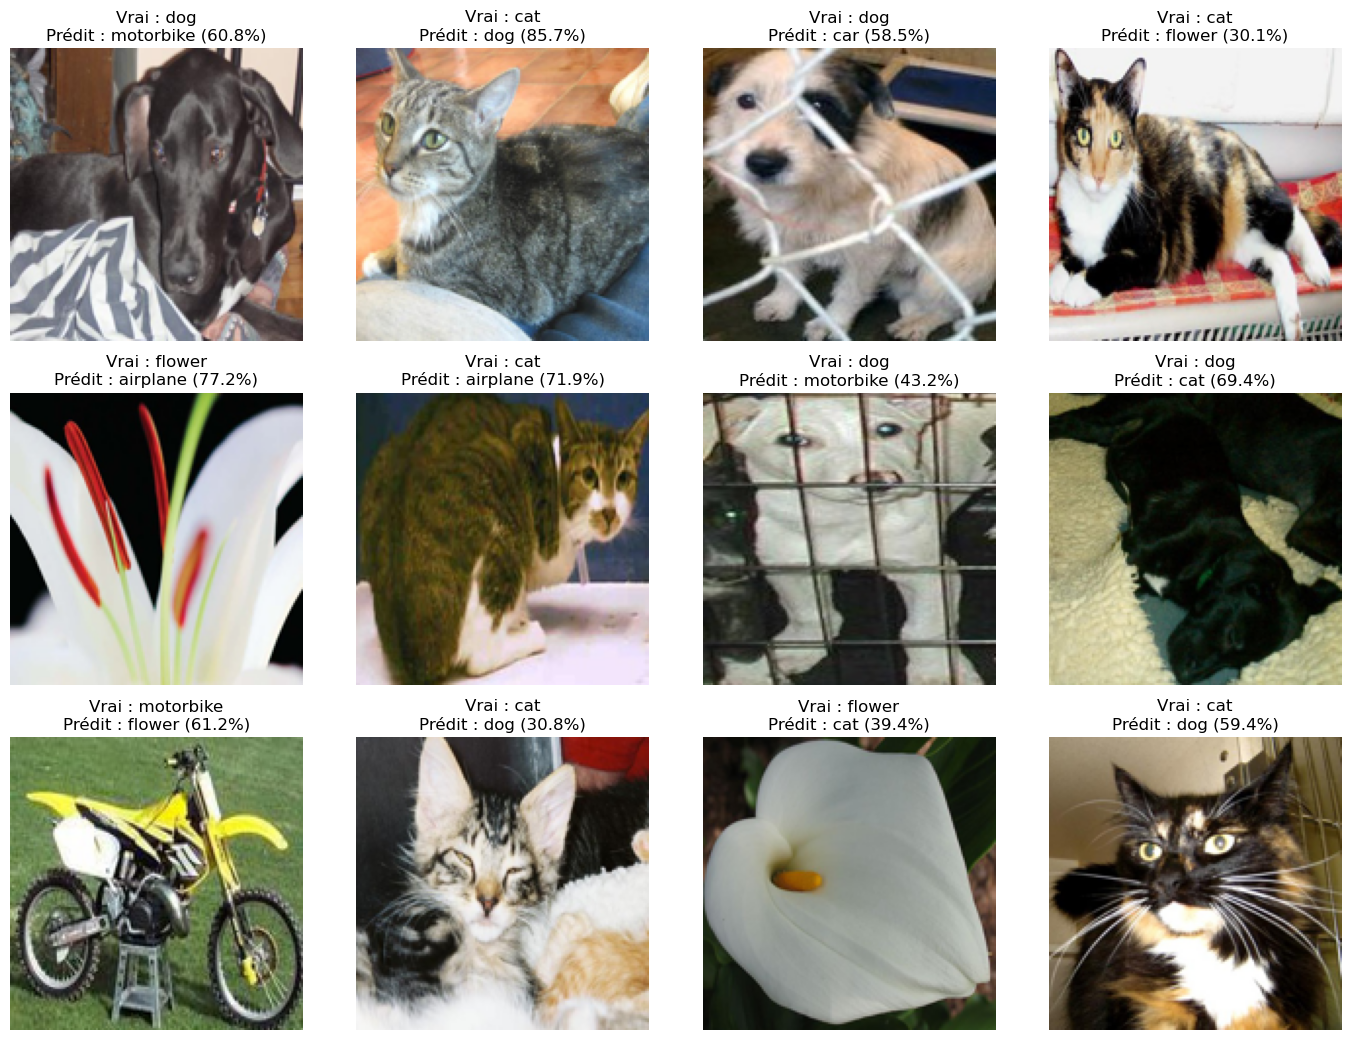

In [18]:
# Montrer des erreurs du modèle sélectionné.
wrong_idx = np.where(pred_selected != y_test)[0]
print(f"Nombre d'erreurs : {len(wrong_idx)} / {len(y_test)}")

# Les images sont dans l'ordre du DataFrame de test car le dataset n'est pas mélangé.
test_paths = test_df["filepath"].tolist()
n_show = min(12, len(wrong_idx))

if n_show:
    cols = 4
    rows = int(np.ceil(n_show / cols))
    plt.figure(figsize=(14, 3.5 * rows))
    for i, idx in enumerate(wrong_idx[:n_show], start=1):
        img = Image.open(test_paths[idx]).convert("RGB").resize(IMG_SIZE)
        true_name = class_names[int(y_test[idx])]
        pred_name = class_names[int(pred_selected[idx])]
        confidence = float(prob_selected[idx].max())
        plt.subplot(rows, cols, i)
        plt.imshow(img)
        plt.title(f"Vrai : {true_name}\nPrédit : {pred_name} ({confidence:.1%})")
        plt.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("Aucune erreur observée sur ce jeu de test.")

### 6.3 Discussion à rédiger

À partir des résultats réellement obtenus, commentez :
1. Quel modèle obtient la meilleure loss et la meilleure accuracy de validation ?
2. L'écart entre les courbes d'entraînement et de validation est-il important ?
3. Le modèle amélioré est-il plus lent ? Son nombre de paramètres est-il supérieur ou inférieur ?
4. Quelles classes sont le plus souvent confondues ? Pourquoi ?
5. L'amélioration est-elle suffisamment importante pour justifier son coût ?

## Partie 7 — Prédiction sur une nouvelle image

Choisissez une image qui n'est pas utilisée dans les partitions d'entraînement, de validation ou de test. Pour évaluer correctement le modèle, privilégiez une image externe dont vous connaissez la vraie classe. La fonction ci-dessous redimensionne l'image en 150 × 150 ; la normalisation est faite dans le modèle lui-même.

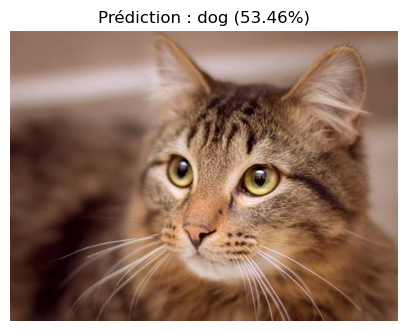

Classe prédite : dog
Score Softmax : 0.5346 (53.46%)

Probabilités par classe :


,classe,probabilité
0,dog,5.345582e-01
1,cat,4.102634e-01
2,airplane,4.093952e-02
3,flower,9.844831e-03
4,person,4.343540e-03
5,car,4.543768e-05
6,motorbike,4.987338e-06
7,fruit,8.125337e-08


In [19]:
# MODIFIEZ ce chemin avec une image externe au dataset.
EXTERNAL_IMAGE_PATH = Path(r"C:\Users\hp\Desktop\image_test.jpg")

def predict_external_image(image_path, model, class_names, true_class=None):
    image_path = Path(image_path)
    if not image_path.exists():
        print(f"Image externe introuvable : {image_path}")
        print("Modifiez EXTERNAL_IMAGE_PATH avec le chemin d'une image réelle.")
        return None

    image = Image.open(image_path).convert("RGB")
    image_resized = image.resize(IMG_SIZE)
    arr = np.asarray(image_resized, dtype=np.float32)
    batch = np.expand_dims(arr, axis=0)  # (1, 150, 150, 3)

    probabilities = model.predict(batch, verbose=0)[0]
    pred_idx = int(np.argmax(probabilities))
    pred_class = class_names[pred_idx]
    confidence = float(probabilities[pred_idx])

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.axis("off")
    plt.title(f"Prédiction : {pred_class} ({confidence:.2%})")
    plt.show()

    print("Classe prédite :", pred_class)
    print(f"Score Softmax : {confidence:.4f} ({confidence:.2%})")
    if true_class is not None:
        print("Vraie classe :", true_class)
        print("Prédiction correcte :", pred_class.lower() == true_class.lower())

    print("\nProbabilités par classe :")
    display(pd.DataFrame({
        "classe": class_names,
        "probabilité": probabilities
    }).sort_values("probabilité", ascending=False).reset_index(drop=True))
    return pred_class, confidence, probabilities

external_result = predict_external_image(
    EXTERNAL_IMAGE_PATH, selected_model, class_names,
    true_class=None  # Ex. "car" si la vraie classe de l'image est connue.
)

### Limites pour une image extérieure aux 8 classes

Le réseau Softmax choisit toujours l'une des huit classes connues, même si l'image représente un objet absent du dataset. Un score Softmax élevé n'est donc pas une preuve que l'image appartient réellement à cette classe. Les prédictions hors distribution nécessitent des méthodes spécifiques de détection d'images inconnues. Si vous testez une image d'une classe connue, renseignez `true_class` pour comparer la prédiction à la vérité terrain.

## Conclusion — modèle et analyse critique

Complétez cette conclusion avec les valeurs affichées par votre exécution :

- **Dataset :** nombre d'images conservées, nombre de classes et difficultés remarquées.
- **CNN initial :** meilleure accuracy/loss de validation et performance de test.
- **CNN amélioré :** meilleure accuracy/loss de validation et performance de test.
- **Modèle retenu :** celui sélectionné à partir de la validation, avec justification.
- **Erreurs :** classes les plus confondues et causes possibles.
- **Limites :** taille du dataset, variabilité des images, temps de calcul et impossibilité de reconnaître de manière fiable une classe inconnue.

**Rappel méthodologique :** ne choisissez pas le modèle en fonction du résultat sur le test. Utilisez la validation pour sélectionner le modèle et gardez le test pour l'évaluation finale.

In [21]:
# Sauvegarder le modèle sélectionné après comparaison.
selected_model.save("modele_images_selectionne.keras")
print(f"Modèle sauvegardé : modele_images_selectionne.keras ({selected_name})")


Modèle sauvegardé avec succès !
